<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Bayesian Statistics One-Shot

_Author:_ Tim Book

In [16]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pymc3 as pm

## Problem 1: Skittles
In a snack-size pack of Skittles, you are concerned with getting an unfair amount of **green Skittles** (the worst flavor). You think there are about 20 skittles per pack. There are 5 different colors of Skittles.

#### A frequentist would...
* Open many packs of skittles and estimate $\hat{p}$ (the proportion of greens).
* Conduct some inference on this data, maybe create a **confidence interval**.

#### A Bayesian (today, you!) would...
* Begin with a preconcieved notion about $p$. This **prior** reflects not just our belief but the _strength_ of our belief.
* Open many packs of skittles.
* Combine our priors with the data and obtain a **posterior distribution** of $p$.
* Make statements about the posterior of $p$, potentially a **credible interval**.

In [2]:
# Skittle data!
n_greens = [
    7, 10, 7, 2, 8, 7, 4, 7, 5, 7,
    3, 9, 5, 4, 5, 1, 4, 3, 3, 4
]

## Let's Collect our Thoughts
Some points:
* We believe there's usually about 20 Skittles per pack
* There are 5 colors
* It would be "fair" if 20% of our Skittles were green. Otherwise, unfair.

So, we'll begin with the following **priors**:
* There are about 20 Skittles per pack. Since this is a count, we can use the **Poisson** distribution to model this value.
* We assume the probability of a "success" (green) is about 20%... but how strong is this belief? We can tune it by messing with the parameters of our **beta** distribution.
* Within a pack, the number of green Skittles would then follow a **binomial** distribution, since each Skittle would be a Bernoulli trial, where "success" is being green.

Let's try this out:

\begin{align}
X | N, p &\sim \text{Bin}(N, p) \\
N &\sim \text{Poi}(20) \\
p &\sim \text{Beta}(16, 4)
\end{align}

In [3]:
# Let's implement this situation using PyMC and sample from the posteriors!
with pm.Model() as model:
    p = pm.Beta('p', 4, 16)
    N = pm.Poisson('N', 20)
    X = pm.Binomial('X', n=N, p=p, observed=n_greens)
    trace = pm.sample(10_000, tune=1_000, init='advi')

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>NUTS: [p]
>Metropolis: [N]
Sampling 4 chains: 100%|██████████| 44000/44000 [00:08<00:00, 5227.69draws/s]
The acceptance probability does not match the target. It is 0.7030704124154363, but should be close to 0.8. Try to increase the number of tuning steps.
The number of effective samples is smaller than 10% for some parameters.


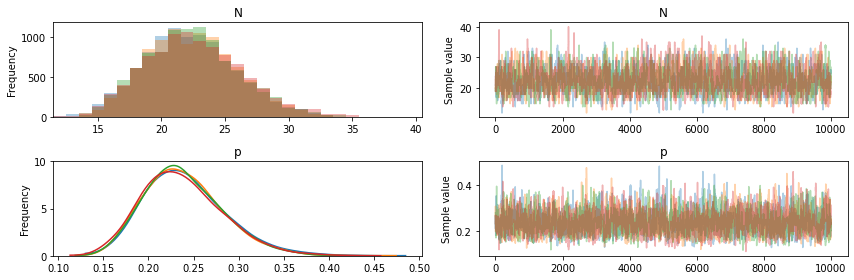

In [4]:
# Let's peek at the traceplots
pm.traceplot(trace);

In [5]:
# What proportion of greens are we actually seeing?
np.mean(trace['p'])

0.23883566223272082

In [6]:
# How many green Skittles *should* we be seeing, then?
np.mean(trace['p']*trace['N'])

5.205006748461542

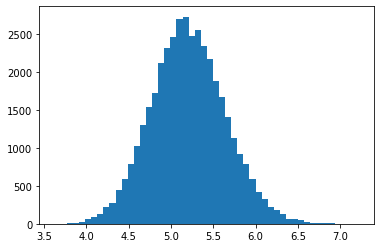

In [7]:
# Overall posterior distribution of p
post_greens = trace['p']*trace['N']
plt.hist(post_greens, bins=50);

In [8]:
# What's the probability of seeing between 5 and 6 green Skittles in a pack?
np.mean((post_greens >= 5) & (post_greens <= 6))

0.639125

## Problem 2: Pay Equity with Bayesian Regression
It is an often-recited statistic that women are paid about 77 cents per dollar a man makes for equal work. But how is this number (and others like it) calculated? While there are many techniques, the following is generally accepted as correct:

We will conduct a **log-regression** based on a person's **legitimate skill level** (ie, things about you that legitimately cause you to be paid more, such as education level and experience) and **an indicator for the protected class**. Written out:

$$\log W = \beta_0 + \beta_1\text{skill} + \beta_2\text{class} + \varepsilon$$

Where $\varepsilon \sim N(0, \sigma)$.

Leaving off the error term for now, we can see by exponentiating both sides:

$$W = e^{\beta_0 + \beta_1\text{skill}} e^{\beta_2\text{class}}$$

That $e^{\beta_2\text{class}}$ is a **multiplicative factor on wage**. That is to say,
* If $\text{class} = 1$ (ie, you are of the protected class), then $e^{\beta_2}$ is the average reduction in pay in relation to $\text{class} = 0$.
* If $\text{class} = 0$ (ie, you are not of the protected class), then $e^0 = 1$, and your wage is unaffected.

So, it is interesting to discover the likelihood that $\beta_2 = 0$ or not. We can actually test this by setting up the prior assumption that $\beta_2$ is 0, and then prove it wrong with data!

In [9]:
# Let's read in the data
# NOTE: IT IS VERY FAKE DATA!!
wages = pd.read_csv('data/wages.csv')
wages.head()

,wage,skill,class
0,89918.887000,0.861868,1
1,48670.977336,0.495555,1
2,36838.979219,0.397853,1
3,111384.622779,0.794007,0
4,85384.347212,0.729693,0


## Let's collect our thoughts again
We know that:
* Since OLS is a GLM, we can lean on our normality assumption that:

$$\log W \sim N(\beta_0 + \beta_1\text{skill} + \beta_2\text{class}, \sigma)$$

* We want to assume $\beta_2$ is 0, but since it's a distributional prior assumption, we'll assume it's tightly centered at 0. Maybe $N(0, 0.1)$.
* We don't actually have any meaningful prior assumptions on $\beta_0$, $\beta_1$, and $\sigma$. So we'll load them up with **noninformative priors**.

### Noninformative Priors
If we:
* don't have any prior beliefs on a parameter or
* we want to let the "data speak for itself",

We can put noninformative priors on it. A **noninformative prior** is one that is so vague, it can't possibly impact the posterior. For example, $N(0, 100)$ is generally noninformative.

### Let's try this set up...
This was my approach, but you can try out other things. Generally, you don't want to "tune" this part of the process, as you run the risk of assuming your own result.

\begin{align}
\log W &\sim N(\beta_0 + \beta_1\text{skill} + \beta_2\text{class}, \sigma) \\
\beta_0 &\sim N(0, 100) \\
\beta_1 &\sim N(0, 100) \\
\beta_2 &\sim N(0, 0.1) \\
\sigma &\sim \text{InverseGamma}(0.01, 0.01)
\end{align}

(The **inverse gamma** distribution is a non-negative distribution similar to the gamma or exponential. Bayesian regression convention is to use IG for measure of variance, but any non-negative distribution will technically work.)

In [10]:
with pm.Model() as model:
    b0 = pm.Normal('b0', 0, 100)
    b1 = pm.Normal('b1', 0, 100)
    b2 = pm.Normal('b2', 0, 0.1)
    sig = pm.InverseGamma('sig', 0.01, 0.01)
    logW = pm.Normal(
        'logW', 
        mu=b0 + b1*wages['skill'] + b2*wages['class'],
        sd=sig,
        observed=np.log(wages['wage'])
    )
    trace = pm.sample(10_000, tune=1_000, init='advi')

Auto-assigning NUTS sampler...
Initializing NUTS using advi...
Average Loss = 77.729:  20%|██        | 40335/200000 [00:16<01:06, 2383.79it/s]    
Convergence achieved at 40400
Interrupted at 40,399 [20%]: Average Loss = 1.3058e+07
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sig, b2, b1, b0]
Sampling 4 chains: 100%|██████████| 44000/44000 [00:23<00:00, 1847.89draws/s]


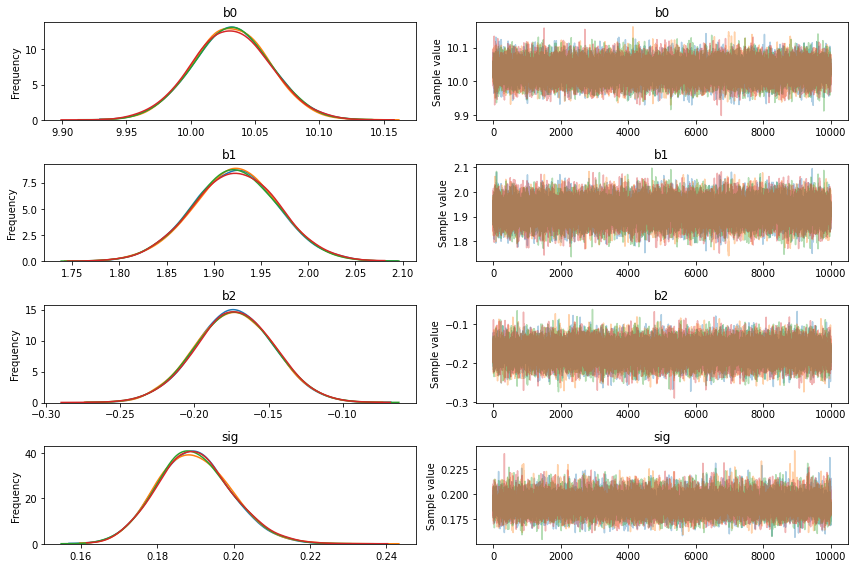

In [11]:
# Look at the traceplots
pm.traceplot(trace);

In [12]:
# Let's analyze the thing we care about: b2
coef = np.exp(trace['b2'])

In [13]:
np.mean(coef)

0.8416373004843972

In [14]:
# Interpretation...
# If we're a member of this protected class, we would expect to make 
# 84cents per dollar that someone not in the protected class makes for
# the same work.

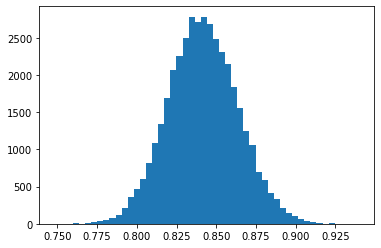

In [15]:
# How stable is this estimation? We can look at the distribution
# and make other kinds of claims if we want!
plt.hist(coef, bins=50);

# Summary
Bayesian statistics is really cool, and it has the capability of answering questions that frequentists can't really grapple with. Here are some quick pros and cons:

### Pros
* We get to use prior subject-matter knowledge in our models
* Our results are full distributions, not just point estimates!
* Thrive with small sample size
* Great for rare events, or events that only happen once (eg, elections)
* Some non-Bayesian models can be adapated to incorporate Bayesian techniques
    - For example, LASSO and Ridge regression result from letting the $\beta$ coefficient vector follow a double-exponential and multivariate normal prior, respectively
    - Bayes nets exist, and some people seem to be excited by that
    
### Cons
* Can get computationally expensive very quickly
* Rarely used in industry, very common in academia
* Higher programming overhead compared to frequentist ML models
* If you wanted, you could "assume your result" while selecting priors. Bayesian statistics often comes under fire for this
* Techniques fall under "white box statistical models" rather than "black box ML models" and thus aren't always amazing at prediction